# 21. Held-out views, frame cost and visible artifacts

[Course plan](../../README.md)

Two models can look equally convincing from the front. After a small turn, one keeps a steady edge while the other reveals a dark spot in empty space. A single flattering frame hides the difference. We can inspect a static scene visually, with a difference map and with a measurement at a pose whose pixels did not participate in training.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'

import photo_diagnostics as inspect_photo

## Where a detail went

Three views of the colored scene supply the gradients and two stay held out. Reference, rendered image and error brightness sit together. A slider amplifies one known change: wider splats, an extra opaque patch in front of the scene, or reduced green. These causes are deliberately controlled. In an actual reconstruction the same visual pattern is a clue for the next experiment.


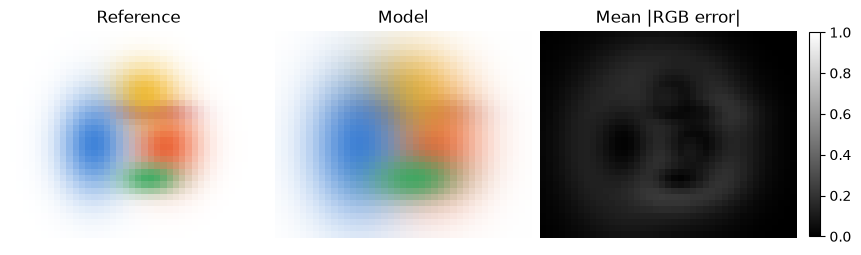

In [2]:
frames, seed = synthetic_capture()
clean, history = fit_colors(seed,frames,steps=12)
def probe(i, kind, strength):
    return error_figure(frames,clean,int(i),kind,strength,lang)
display(probe(1,"blur",.45)); plt.close()
controls(probe,i=list(range(5)),kind=["blur","floater","tint"],strength=(0,1,.05,.45))


## A fair image pair comes first

Held out means the frame’s RGB values were excluded from parameter fitting. The camera pose is known during evaluation. The three training views tell us how well the model fitted its inputs. The other two tell us how its shapes carry across viewpoints. Near-duplicates from a nearly stationary burst provide little evidence about a wide change of angle. Views used to choose learning rates or iteration counts belong to a separate validation set. Repeatedly tuning against a test frame changes its role.

The pixel comparison needs the same camera, resolution, crop and background. Suppose four normalized red target values are $[0.2,0.4,0.6,0.8]$ and the predictions are $[0.3,0.4,0.4,0.9]$. Subtracting the target at each position gives $[0.1,0,-0.2,0.1]$. Their sum is zero despite three wrong values. The absolute differences sum to $0.4$, so mean absolute error is $0.4/4=0.1$. The squares sum to $0.01+0+0.04+0.01=0.06$. Mean squared error is $0.06/4=0.015$.

Each RGB channel supplies one comparison. A 40 × 30 frame therefore contributes $40\cdot30\cdot3=3600$ numbers. A map pixel on the right shows the mean of three **absolute** errors. If only red differs by 0.3, its map value is $0.3/3=0.1$. Exposure, color space, background mask and crop can all affect the metric with identical geometry. These examples compare decoded RGB in [0,1] without a conversion to linear light.


In [3]:
reference = np.array([.2,.4,.6,.8])
predicted = np.array([.3,.4,.4,.9])
print("residual:", (predicted-reference).round(3))
print(scores(predicted,reference))
assert np.isclose(scores(predicted,reference)["mse"], .015)


residual: [ 0.1  0.  -0.2  0.1]
{'mae': 0.09999999999999998, 'mse': 0.014999999999999993, 'psnr': 18.23908740944319}


## The same score can describe two different pictures

Two gray 16 × 16 squares start at 0.5 in all three channels. In the first copy, add 0.05 everywhere. In the second, add 0.2 inside a 4 × 4 patch. The pictures tell different stories: a small exposure shift across the frame, or a bright blemish on a gray surface.

In the first case each of the 256 pixels has squared error $0.05^2=0.0025$. In the second, just $4\cdot4=16$ of the 256 pixels changed. Each contributes $0.2^2=0.04$, so the frame mean is $(16/256)\cdot0.04=0.0025$. All channels agree, so averaging RGB changes nothing. The mean **absolute** errors do differ: 0.05 versus $(16/256)\cdot0.2=0.0125$. Squaring gave the occasional larger miss more influence. Either average still discards position. Moving the patch to a corner leaves both scores unchanged. The map shows whether the blemish landed on the silhouette or on empty background.

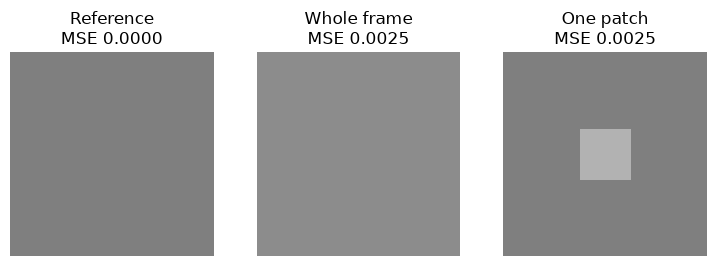

In [4]:
gray = np.full((16,16,3),.5)
shift = gray+.05
patch = gray.copy(); patch[6:10,6:10] += .2
fig,axes=plt.subplots(1,3,figsize=(7.4,2.55),layout="constrained")
labels = ["Эталон","Весь кадр","Один участок"] if lang=="ru" else ["Reference","Whole frame","One patch"]
for ax,im,title in zip(axes,[gray,shift,patch],labels):
    metric=scores(im,gray)
    ax.imshow(im,interpolation="nearest")
    ax.set_title(f"{title}\nMSE {metric['mse']:.4f}"); ax.axis("off")
plt.show()
assert np.isclose(scores(gray,shift)["mse"],scores(gray,patch)["mse"])

## Why decibels appear

PSNR uses the same MSE and reverses the direction of the scale. Let $A$ be the peak channel value in **the chosen representation**, for example 1. Then

$$
\mathrm{PSNR}=10\log_{10}\!\left(\frac{A^2}{\mathrm{MSE}}\right).
$$

Squaring the peak puts it in the same units as the error. Dividing by the error in the example gives $1/0.015\approx66.67$. The base-10 logarithm asks which exponent of 10 gives 66.67. The answer is about 1.824. Multiplication by 10 gives 18.24 dB. Halving MSE adds $10\log_{10}2\approx3.01$ dB. An exact match has zero error and conventionally infinite PSNR. For bytes with peak 255, both $A$ and the measured MSE change. A numerator of 255 squared with a normalized denominator mixes the units.

A mean of frame-level logarithms differs from the logarithm of a mean error. For two equal-sized frames with MSE values 0.01 and 0.09, PSNR is 20 and about 10.46 dB. Their average is about 15.23 dB. Their pooled MSE is 0.05, giving about 13.01 dB. The table below keeps a separate row per camera so that a hard view remains visible.


In [5]:
for split in ("train","test"):
    for row in evaluate(clean,frames,split):
        print(split, row["name"], "MSE", round(row["mse"],7), "PSNR", round(row["psnr"],2))


train view_-32.png MSE 8.6e-06 PSNR 50.67
train view_+00.png MSE 1.52e-05 PSNR 48.19
train view_+35.png MSE 4.19e-05 PSNR 43.78
test view_-15.png MSE 9.1e-06 PSNR 50.43
test view_+21.png MSE 3.03e-05 PSNR 45.19


## Another view of the same sculpture

The real photograph view-04 was absent from the eight training images. The larger example uses 117 splats initialized from sparse points and refined for 1,200 steps on sampled training pixels. Evaluation uses the full 80 × 60 image. Both images in each comparison must have the same dimensions. This model recovers more of the silhouette, although its edges and fine texture remain soft. When a capture stays on one side of an object, its back surface remains uncertain even in a large model. [Photographs by NVIDIA Corporation, PhysicalAI-NuRec-PPISP, CC BY 4.0](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example) · [Reproducible training](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)


view-04.jpg {'mae': 0.07100254932146274, 'mse': 0.009817480629714553, 'psnr': 20.079999469372364}


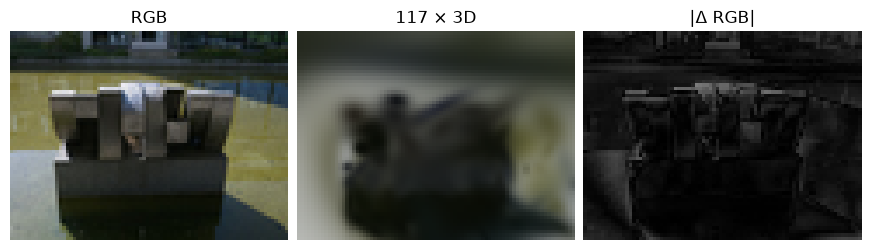

In [6]:
from reconstruction_demos import ROOT
photos, _ = photo_capture(max_side=80)
reference_path = ROOT / "site/dist/assets/reconstruction/photo-reference.json"
photo_model = json.loads(reference_path.read_text(encoding="utf8"))
image = next(f for f in photos if f["split"]=="test")
h,w = image["rgb"].shape[:2]
result = render_scene(photo_model,image["camera"],w,h)
print(image["name"], scores(result,image["rgb"]))
fig, ax = plt.subplots(1,3,figsize=(8.6,3),layout="constrained")
for a,title,im in zip(ax, ["RGB", "117 × 3D","|Δ RGB|"], [image["rgb"],result,np.abs(result-image["rgb"]).mean(axis=2)]):
    a.imshow(im,cmap="gray",vmin=0,vmax=1);a.set_title(title);a.axis("off")
plt.show()


## How much error falls on the subject?

The photograph has 80 × 60 pixels. A 40 × 30 box covers 1,200 of the 4,800 pixels, one quarter of the frame. It starts in the center, covering columns 20 through 59 and rows 15 through 44 inclusive. It is an ordinary rectangle containing both stone and some background. The same calculation works with an independently checked subject mask of any shape.

The map shows the root mean square deviation **at one pixel**. The three channel residuals are squared and averaged, then a square root restores the channel scale. For example, $(0.3,0,0)$ gives $\sqrt{(0.09+0+0)/3}\approx0.173$. Zero is dark and one is the top of the scale. A bright trace locates a discrepancy without telling which channel was too high.

With the box in the center, its MSE is about 0.011932. Outside it, MSE is 0.009113. The full-frame mean is $0.25\cdot0.011932+0.75\cdot0.009113\approx0.009817$. The factors 0.25 and 0.75 are area fractions. To find the share of **total** squared error inside, divide the first region’s contribution by the whole result. That gives $0.25\cdot0.011932/0.009817\approx0.304$, about 30.4%. A quarter of the frame accounts for just under a third of the error. Moving the box leaves global MSE unchanged. It changes the answer to a different question: where did the model lose image quality?

<details><summary>Can one carefully chosen rectangle settle which model is better?</summary>

A box chosen after seeing the predictions can easily favor one model on a convenient patch. A comparison can use the same predetermined mask, the same cameras and a shared map scale. Keeping the full frame beside the mask also reveals the cost of a local gain. A sharper piece of stone might come with a new blotch in the background.

</details>

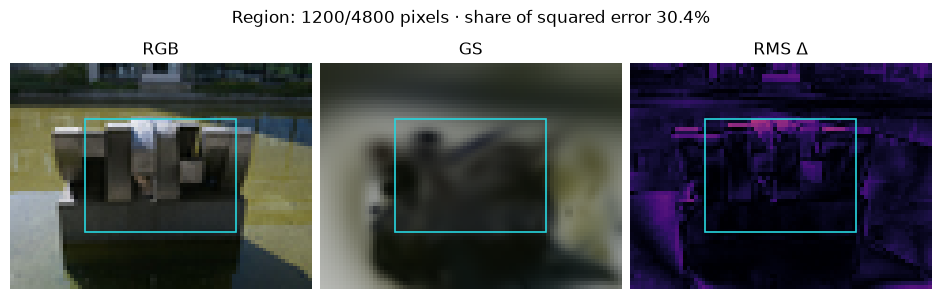

In [7]:
def inspect_region(left,top):
    return inspect_photo.region_figure(image["rgb"],result,int(left),int(top),lang=lang)
display(inspect_region(20,15)); plt.close()
controls(inspect_region,left=(0,40,1,20),top=(0,30,1,15))

## Reading different traces

**A floater.** An erroneous depth can hide in one image. Moving the camera slightly makes a dark patch slip off a surface and cover the background. A short arc around frozen geometry exposes the displacement. Excessive movement relative to the background points toward the patch’s depth; checking camera poses and feature tracks helps separate pose errors.

**Blur.** An enlarged Gaussian leaves residuals along an edge. Motion blur in the inputs, a coarse model or misaligned camera poses can leave a similar trace. Comparing the source sharpness and the projected sparse points helps distinguish them. Extra splats fitted to misregistered images can simply memorize the disagreement.

**Flicker.** A tiny change of angle suddenly changes color. Reordering translucent splats at similar depths, exaggerated directional appearance and insufficient filtering of small footprints can produce similar effects. A sequence of adjacent camera poses with the scene frozen exposes the jump. A single-frame score says little about it.

**Tint.** Reducing green leaves an error across a familiar surface. If the bias is similar in every view, exposure and RGB processing are worth isolating. If its sign changes with camera angle, directional color deserves a separate look.

The authors also report **SSIM** and **LPIPS**. SSIM compares brightness and the joint local pattern across windows. The gray windows $[0.2,0.8]$ and $[0.3,0.7]$ have the same mean, 0.5. Their deviations are $[-0.3,0.3]$ and $[-0.2,0.2]$. Mean squared deviations are 0.09 and 0.04, and their mean product is 0.06. In this window the brightness factor is 1; contrast and correspondence contribute $(2\cdot0.06+0.0009)/(0.09+0.04+0.0009)\approx0.924$. The small constant keeps the denominator away from zero. Full SSIM slides windows across the image and averages their scores. LPIPS measures differences between learned image features; its value depends on the network and preprocessing. All else equal, greater similarity gives higher SSIM and lower LPIPS. Comparisons with a published evaluation require the same metric implementations and protocol. [Authors’ evaluation code](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/metrics.py)


## A one-pixel shift or a blurred edge?

Consider a sharp step with brightness 0.2 on the left and 0.8 on the right. One “reconstruction” keeps the edge sharp but moves it one column to the right. The other keeps it in place and mixes in a quarter of each neighbor. In a small picture both can look like halos. The signed error $E=P-Y$ separates the cases. After the shift, one column shows 0.2 in place of 0.8, hence $E=-0.6$. Symmetric blur brightens the left edge from 0.2 to 0.35 and darkens the right edge from 0.8 to 0.65. It leaves two adjacent traces of opposite signs: $+0.15$ and $-0.15$.

On real stone the trace is a clue, not a diagnosis. A focal-length or resize error can move edges too, with a growing displacement towards the corners. Projecting the sparse points onto an original image separates some of these causes before training. If those projections drift towards the edges as well, the calibration, crop and resize deserve a look. If the points register and the photos are sharp, the shapes of the splats covering a small blurred region make a more informative next experiment.

Flicker calls for another measurement. Suppose a corresponding detail in two nearby photographs goes from 0.50 to 0.52, while the render goes from 0.48 to 0.68. The observed change is $0.52-0.50=0.02$. The predicted change is 0.20. The excess jump is $0.20-0.02=0.18$. Since camera motion usually displaces the detail, it has to be matched across the images. Comparing a fixed column number could compare stone in one frame with background in the other. On a path without photographs the jump is visible, but its deviation from a real change in highlight remains unknown.

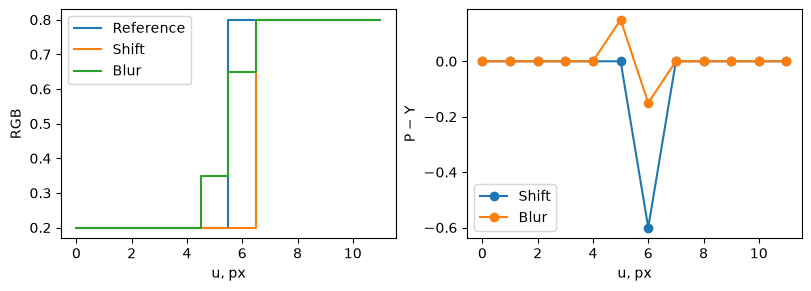

In [8]:
edge = np.r_[np.full(6,.2),np.full(6,.8)]
offset = np.r_[edge[0],edge[:-1]]
blur = np.convolve(np.pad(edge,1,mode="edge"),[.25,.5,.25],mode="valid")
fig,axes = plt.subplots(1,2,figsize=(8,2.8),layout="constrained")
labels = ["Эталон","Сдвиг","Размытие"] if lang=="ru" else ["Reference","Shift","Blur"]
for a,title in zip((edge,offset,blur),labels):
    axes[0].step(range(len(a)),a,where="mid",label=title)
for a,title in zip((offset,blur),labels[1:]):
    axes[1].plot(a-edge,"o-",label=title)
axes[0].set(xlabel="u, px",ylabel="RGB"); axes[1].set(xlabel="u, px",ylabel="P − Y")
for ax in axes: ax.legend()
plt.show()
assert np.allclose((blur-edge)[5:7],[.15,-.15])

## What a frame costs

The teaching model stores 14 numbers per splat, $3+3+4+3+1$. Packed as four-byte float32 values, that is $14\cdot4=56$ bytes per splat and $117\cdot56=6552$ bytes for 117 splats. This is **the numerical payload**. The JSON file also stores keys, brackets and decimal digits. Python lists and dictionaries carry their own overhead in memory. Training additionally needs gradients, Adam state, intermediate images and the computation graph. Spherical harmonics change the parameter count in the full model.

The code below separately reports the actual JSON file size and times rendering without file I/O or plotting. A warm-up frame precedes the median of five timed calls. If a frame takes 20 milliseconds, one second contains 1,000 milliseconds, so $1000/20=50$ frames per second for sequential calls. A comparison of two renderers uses the same scene, cameras, resolution and hardware. A comparison of two candidate scenes can allow different splat counts. The renderer, hardware, trajectory and frame size stay fixed, and each scene’s count is recorded alongside its quality and timing. CUDA timings need synchronization or GPU events, or the clock can measure only the time taken to enqueue work.


A separate measurement enables tracemalloc around one warmed-up render. The peak counts the maximum simultaneously allocated bytes visible to Python’s allocation tracer, including library allocations registered with it. Timing runs separately. The already-loaded model, complete process memory, driver allocations and VRAM are outside this measurement.

In [9]:
ms = benchmark(lambda: render_scene(photo_model,image["camera"],w,h),repeats=5)
print("resolution:", w,h," · CPU median ms:",round(ms,3))
print("frames/s:", round(1000/ms,2))
print("float32 payload B:", len(photo_model["splats"])*14*4, "JSON file B:", reference_path.stat().st_size)

import tracemalloc
tracemalloc.start()
try:
    rendered = render_scene(photo_model,image["camera"],w,h)
    _, peak_bytes = tracemalloc.get_traced_memory()
finally:
    tracemalloc.stop()
print("traced CPU render peak (bytes):", peak_bytes)


resolution: 80 60  · CPU median ms: 58.698
frames/s: 17.04
float32 payload B: 6552 JSON file B: 39038
traced CPU render peak (bytes): 738194


## An experiment

A larger model raises PSNR only on training views and takes longer per frame. Which comparison would show what actually improved?

<details><summary>Worked answer</summary>

Both models can be rendered from the same held-out cameras, with the reference, both predictions and error maps on a common scale. Lower training error can mean a better-known detail, a memorized highlight, or an extra splat behind a surface. The held-out pair shows whether that improvement travels with the camera. Frame time and model size are measured separately under equal conditions.

</details>


## Where the experiment ends

View-04 comes with a reference RGB image, a model, a pose, a resolution and a comparison protocol. On a free orbit there is just the model and a moving camera. The two checks answer different practical questions: how far the prediction missed an observed view, and what begins to behave strangely in motion.

<details><summary>Which of two models, A and B, can serve a 30-frame-per-second viewer?</summary>

Suppose A renders in 22 ms and B in 38 ms on the same device at the same resolution. The frame budget is $1000/30\approx33.3$ ms. A leaves about 11.3 ms for the rest of the frame, while B exceeds the budget by roughly 4.7 ms even if its PSNR is higher. The median describes a typical frame. Smooth motion also depends on the slow frames along the same camera path. If B resolves a valuable detail, the next fair pair would compare both models at a common budget with the same camera, resolution and mask, with timing and quality shown side by side. Lowering the resolution only for B would change two conditions at once.

</details>

For another capture the result can be kept in concrete form: training and held-out frame names, the scene, render settings, a table by camera, a photograph with its error map and a short path through the trouble spot. A suspicion such as “the smallest splats flicker” then becomes testable. The scene and cameras stay fixed, only the filter changes, and the comparison uses the same region and motion. That closes the path from a single Gaussian to evaluating a whole static scene.